# Evaluación Sumativa 3
## Informe técnico de modelos avanzados: ARFIMA / GARCH
### Análisis de Series de Tiempo — MCDI505

| | |
|---|---|
| **Estudiante** | Claudio Rodolfo Alarcón Pradenas |
| **Docente** | Dr. Harvey Jezlid Rosas Quintero |
| **Evaluación** | Sumativa 3 · Semana 3 · Fase 3 · 18 de octubre de 2026 |
| **Archivo** | `mcdi505_s3calarcon.ipynb` |
| **Datos** | `data/raw/consumo_electrico_litoral_depurado.csv` |
| **Repositorio (respaldo y reproducibilidad)** | `https://github.com/claudioalarconP/Analisis_de_serie_de_tiempo` |

**Pregunta de la semana:** ¿la memoria larga o la volatilidad condicional aportan algo al SARIMA seleccionado en la Sumativa 2?

## Hoja de decisiones

Punto de partida: **M4 = SARIMA(0,1,0)(1,1,0)₁₂** sobre log(consumo), sin variables exógenas, reestimado con 2015-01 a 2022-12 y validado en 2023 (2024 no se usa).

| Criterio | Decisión o conclusión | Evidencia clave (cifra, prueba o figura) | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Memoria larga | No hay evidencia suficiente de memoria larga; ARFIMA(0,d,0) queda como contraste. | H = 0,584 y d = 0,084 (n = 83); el 60,5 % de los ruidos blancos simulados iguala o supera ese H (Fig. 2). ACF sin decaimiento lento: solo el rezago 24 (−0,35) sale de ±0,215, y es negativo, aislado y sin vecinos significativos (Fig. 1). Con ARFIMA, Ljung-Box K = 24 pasa de p = 0,059 a 0,023. | SARIMA M4 + ARFIMA(0,d,0) como modelo final | No se incorpora la diferenciación fraccional; el rezago 24 queda como aspecto a observar. |
| 2. Volatilidad | No hay evidencia estadística suficiente de heterocedasticidad condicional; GARCH(1,1) queda como contraste. | Ljung-Box de residuos² (K = 12): p = 0,829; ARCH-LM: p = 0,786. GARCH(1,1): ω = 0,1565, α = 0,0687, β = 0,7716, α + β = 0,8403; z_t y z_t²: p ≈ 0,77 y 0,85. AIC: 237,5 con varianza constante y 240,4 con GARCH. La principal alza de σ_t sigue al shock de 2020 y se disipa (Tabla 1, Fig. 3–5). | GARCH(1,1) como modelo necesario de la varianza | En el consumo eléctrico mensual, sin agrupamiento persistente de volatilidad tras el SARIMA, se mantiene la varianza constante. |
| 3. Contraste con el modelo clásico | ARFIMA no mejora al SARIMA y GARCH no mejora de forma sustantiva los intervalos. | RMSE / MAE 2023 (GWh): SARIMA M4 4,12 / 3,71; con ARFIMA 4,19 / 3,75; naive 7,26 / 6,53. Cobertura 12/12 en ambos intervalos; ancho medio 46,26 (SARIMA) y 45,64 GWh (GARCH) (Tabla 2). | Comparar ARFIMA y GARCH por AIC (modelan aspectos distintos) | El contraste no justifica agregar complejidad al SARIMA. |
| 4. Selección del modelo | Se mantiene M4 = SARIMA(0,1,0)(1,1,0)₁₂ para la Semana 4. | Menor RMSE y MAE en 2023, 43,3 % (RMSE) y 43,2 % (MAE) menos error que el naive estacional, cobertura 12/12 con un solo coeficiente (Tabla 3, Fig. 7). | SARIMA M4 + ARFIMA(0,d,0) y SARIMA M4 + bandas GARCH(1,1) | M4 pasa a la Semana 4 sin cambios. Limitaciones: subestima 9 de 12 meses (−2,8 % en el total anual) y conserva el rezago 24 residual. |

*Correcciones respecto de la Formativa 3, según la retroalimentación:* lectura del rezago 24 (fila 1 y §1), contexto del consumo eléctrico en la volatilidad (fila 2 y §2) y declaración de IA detallada (sección final). Se corrigió además la reducción de error frente al naive (43,3 % en RMSE y 43,2 % en MAE, antes informada como 43,2 % en ambas).

## 0. Configuración, datos y punto de partida

In [1]:
import warnings
import hashlib                                         # agregado: huella del CSV (reproducibilidad)
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import statsmodels
from scipy.optimize import minimize
from scipy.special import gammaln                      # agregado: ACF teórica de un ARFIMA(0,d,0) (figura 1)
from IPython.display import display                    # agregado: tablas
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf              # agregado: valores numéricos de la ACF
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
warnings.filterwarnings("ignore")
SEMILLA = 505
np.random.seed(SEMILLA)

# Estilo de figuras (el mismo de la Sumativa 2)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
                     "axes.titlesize": 11, "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False})
ROJO, AZUL, GRIS, VERDE, NARANJA = "#b30338", "#0057b8", "#9e9e9e", "#2e7d32", "#ef6c00"

In [2]:
# ==============================================================================
# Funciones de apoyo (las mismas de la Sesión 3, más tres envoltorios para DEL)
# No necesita modificarlas.
# ==============================================================================

def calcular_exponente_hurst(serie, min_ventana=8, max_ventana=None, n_ventanas=10):
    """Exponente de Hurst por Rango Reescalado (R/S). Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    if max_ventana is None:
        max_ventana = n // 4
    ventanas = np.unique(np.geomspace(min_ventana, max_ventana, num=n_ventanas, dtype=int))
    rs_promedio, ventanas_validas = [], []
    for w in ventanas:
        m = n // w
        if m < 1:
            continue
        rs_bloques = []
        for i in range(m):
            bloque = serie[i * w:(i + 1) * w]
            recorrido = np.cumsum(bloque - np.mean(bloque))
            desviacion = np.std(bloque)
            if desviacion > 0:
                rs_bloques.append((np.max(recorrido) - np.min(recorrido)) / desviacion)
        if rs_bloques:
            rs_promedio.append(np.mean(rs_bloques))
            ventanas_validas.append(w)
    pendiente, _ = np.polyfit(np.log(ventanas_validas), np.log(rs_promedio), 1)
    return pendiente


def aplicar_filtro_fraccional(serie, d):
    """Operador (1-B)^d. d > 0 diferencia fraccionalmente; d < 0 integra. Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    pesos = np.zeros(n)
    pesos[0] = 1.0
    for k in range(1, n):
        pesos[k] = pesos[k - 1] * (k - 1 - d) / k
    return np.array([np.sum(pesos[:t + 1] * serie[t::-1]) for t in range(n)])


def garch_log_verosimilitud_negativa(parametros, serie):
    """Log-verosimilitud negativa de un GARCH(1,1) gaussiano. Ver Sesión 3, §3.4."""
    omega, alpha, beta = parametros
    sigma2 = np.zeros(len(serie))
    sigma2[0] = np.var(serie)
    for t in range(1, len(serie)):
        sigma2[t] = omega + alpha * serie[t - 1] ** 2 + beta * sigma2[t - 1]
    if np.any(sigma2 <= 1e-8):
        return 1e10
    return 0.5 * np.sum(np.log(2 * np.pi) + np.log(sigma2) + serie ** 2 / sigma2)


def correccion_arfima(residuos, d, h):
    """Pronóstico h pasos del componente ARFIMA(0,d,0) de los residuos.

    Diferencia fraccionalmente los residuos con d, pronostica cero (ruido blanco)
    y vuelve a integrar con -d. Lo que queda es la persistencia que la memoria
    larga añadiría al pronóstico del SARIMA (en escala logarítmica).
    """
    r = np.asarray(residuos, dtype=float)
    extendida = np.concatenate([aplicar_filtro_fraccional(r, d), np.zeros(h)])
    return aplicar_filtro_fraccional(extendida, -d)[len(r):]


def estimar_garch11(residuos, h):
    """Estima un GARCH(1,1) por MLE sobre los residuos estandarizados.

    Devuelve un diccionario con omega, alpha, beta, persistencia, convergencia,
    residuos estandarizados por sigma_t y el factor de escala de la desviación
    estándar condicional para los h meses siguientes (1 = igual a la varianza
    incondicional).
    """
    r = np.asarray(residuos, dtype=float)
    s = r.std()
    u = r / s
    res = minimize(garch_log_verosimilitud_negativa, x0=[0.05, 0.10, 0.80], args=(u,),
                   bounds=[(1e-6, 5.0), (1e-6, 0.999), (1e-6, 0.999)],
                   constraints=({"type": "ineq", "fun": lambda p: 0.999 - p[1] - p[2]},),
                   method="SLSQP")
    om, al, be = res.x
    sigma2 = np.zeros(len(u)); sigma2[0] = u.var()
    for t in range(1, len(u)):
        sigma2[t] = om + al * u[t - 1] ** 2 + be * sigma2[t - 1]
    futura = np.zeros(h)
    futura[0] = om + al * u[-1] ** 2 + be * sigma2[-1]
    for i in range(1, h):
        futura[i] = om + (al + be) * futura[i - 1]
    incondicional = om / (1 - al - be)
    return {"omega": om, "alpha": al, "beta": be, "persistencia": al + be,
            "convergencia": bool(res.success),
            "residuos_estandarizados": u / np.sqrt(sigma2),
            "escala_futura": np.sqrt(futura / incondicional)}


def metricas(real, pred):
    """RMSE y MAE en la escala de los datos (GWh)."""
    e = np.asarray(real, float) - np.asarray(pred, float)
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e)))}


def cobertura_y_ancho(real, inferior, superior):
    """Proporción de meses dentro del intervalo y ancho promedio del intervalo (GWh)."""
    real, inferior, superior = (np.asarray(x, float) for x in (real, inferior, superior))
    return {"Cobertura": float(np.mean((real >= inferior) & (real <= superior))),
            "Ancho medio": float(np.mean(superior - inferior))}

In [3]:
# Adaptación mínima: el CSV se busca con rutas relativas (junto al notebook o en data/, data/raw, data/processed),
# igual que en la Sumativa 2, para que el notebook corra dentro de la estructura del repositorio.
ARCHIVO = "consumo_electrico_litoral_depurado.csv"
rutas = [Path(*[".."] * n) / sub / ARCHIVO for n in range(5) for sub in (".", "data", "data/raw", "data/processed")]
ruta = next((r for r in rutas if r.exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No se encontró {ARCHIVO}: ubíquelo junto al notebook o en data/, data/raw o data/processed.")

df = pd.read_csv(ruta, parse_dates=["fecha"], index_col="fecha")
df.index.freq = "MS"
y = df["consumo_gwh"]
log_y = np.log(y)

# Partición oficial: entrenamiento 2015-2022, validación 2023. 2024 no se utiliza esta semana.
H = 12
log_train, log_val = log_y[:"2022-12"], log_y["2023-01":"2023-12"]
y_val = y["2023-01":"2023-12"]
assert len(log_train) == 96 and len(log_val) == 12 and log_val.index.max() == pd.Timestamp("2023-12-01")
print(f"Entrenamiento: {len(log_train)} meses ({log_train.index[0]:%Y-%m} a {log_train.index[-1]:%Y-%m}) | "
      f"Validación: {len(log_val)} meses ({log_val.index[0]:%Y-%m} a {log_val.index[-1]:%Y-%m}) | frecuencia: {log_train.index.freqstr}")
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
      f"statsmodels {statsmodels.__version__} | SHA-256 del CSV: {hashlib.sha256(ruta.read_bytes()).hexdigest()[:16]}…")

Entrenamiento: 96 meses (2015-01 a 2022-12) | Validación: 12 meses (2023-01 a 2023-12) | frecuencia: MS
Python 3.13.16 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | statsmodels 0.15.0 | SHA-256 del CSV: d308b3605bf47ed8…


In [4]:
# ==============================================================================
# Modelo seleccionado en la Sumativa 2: M4 = SARIMA(0,1,0)(1,1,0)12 sobre log(y), sin variables exógenas
# (M6, con `covid` y `agudo`, fue solo un análisis complementario en la S2 y no participa en el flujo de la S3)
# ==============================================================================
ORDEN = (0, 1, 0)
ORDEN_ESTACIONAL = (1, 1, 0, 12)
USAR_COVID = False

EXOGENAS = ["covid"] if USAR_COVID else None
MODELO = "SARIMA M4"                                                        # etiqueta de tablas y figuras
N_ARMA = ORDEN[0] + ORDEN[2] + ORDEN_ESTACIONAL[0] + ORDEN_ESTACIONAL[2]    # parámetros ARMA (gl de Ljung-Box)

assert ORDEN is not None and ORDEN_ESTACIONAL is not None, "Complete ORDEN y ORDEN_ESTACIONAL con su modelo de la Sumativa 2."
assert EXOGENAS is None, "el modelo base de la Sumativa 3 (M4) no lleva variables exógenas"

In [5]:
# Reestimación del SARIMA M4 sobre el entrenamiento 2015-01 a 2022-12 (escala logarítmica, sin exógenas)
X_train = df[EXOGENAS].astype(float)[:"2022-12"] if EXOGENAS else None
X_val = df[EXOGENAS].astype(float).loc["2023-01":"2023-12"] if EXOGENAS else None

# Misma estimación de la Sumativa 2: L-BFGS con maxiter = 200 y, si no converge, Powell desde el mismo punto
modelo_sarima = SARIMAX(log_train, exog=X_train, order=ORDEN, seasonal_order=ORDEN_ESTACIONAL)
sarima = modelo_sarima.fit(disp=False, maxiter=200)
if not sarima.mle_retvals.get("converged", True):
    sarima = modelo_sarima.fit(start_params=sarima.params, method="powell", maxiter=1000, disp=False)
assert sarima.mle_retvals.get("converged", True), "M4 no converge: revisar antes de continuar"
assert sarima.nobs == 96 and sarima.fittedvalues.index.max() == pd.Timestamp("2022-12-01"), "el ajuste no debe ver 2023 ni 2024"

inicio = ORDEN[1] + ORDEN_ESTACIONAL[1] * ORDEN_ESTACIONAL[3]      # se descartan las primeras d + D·s observaciones
residuos = sarima.resid.iloc[inicio:]

pron = sarima.get_forecast(H, exog=X_val)
media_log = pron.predicted_mean
ic_log = pron.conf_int(alpha=0.05)
sd_log = (ic_log.iloc[:, 1] - media_log) / 1.96
assert media_log.index.equals(y_val.index), "el pronóstico debe corresponder a 2023"

# Retransformación a GWh: media con corrección de sesgo exp(m + s²/2), como en la Sumativa 2; IC 95 % por cuantiles
media_gwh = np.exp(media_log + sd_log ** 2 / 2)
inf_sarima, sup_sarima = np.exp(media_log - 1.96 * sd_log), np.exp(media_log + 1.96 * sd_log)

naive = y["2022-01":"2022-12"].to_numpy()                          # naive estacional
real = y_val.to_numpy()
met_sarima = metricas(real, media_gwh)
print(f"{MODELO} = SARIMA{ORDEN}{ORDEN_ESTACIONAL} | exógenas: {EXOGENAS} | AIC = {sarima.aic:.1f} | "
      f"convergencia: {sarima.mle_retvals.get('converged')}")
print(f"Residuos utilizables: {len(residuos)} ({residuos.index[0]:%Y-%m} a {residuos.index[-1]:%Y-%m}) | "
      f"pronóstico: {media_gwh.index[0]:%Y-%m} a {media_gwh.index[-1]:%Y-%m}")

# --- Contraste con la Sumativa 2 (coeficiente y métricas publicadas para M4) ---
COEF_S2 = {"ar.S.L12": -0.311}
METRICAS_S2 = {"RMSE": 4.12, "MAE": 3.71}
llf_s2 = sarima.model.loglike(np.r_[list(COEF_S2.values()), sarima.params["sigma2"]])
print("Coeficiente S2 → reestimado: " + " | ".join(f"{k} {v:+.3f} → {sarima.params[k]:+.3f}" for k, v in COEF_S2.items())
      + f" | σ² = {sarima.params['sigma2']:.5f}")
print(f"log-verosimilitud: reestimada = {sarima.llf:.3f} | evaluada en el coeficiente de la S2 = {llf_s2:.3f} "
      f"(diferencia = {sarima.llf - llf_s2:.3f})")
print(f"Validación 2023 ({MODELO}): RMSE = {met_sarima['RMSE']:.3f} GWh | MAE = {met_sarima['MAE']:.3f} GWh "
      f"(Sumativa 2: {METRICAS_S2['RMSE']:.2f} y {METRICAS_S2['MAE']:.2f})")
assert all(abs(met_sarima[k] - v) < 0.01 for k, v in METRICAS_S2.items()), "las métricas difieren de la Sumativa 2: revisar"

# --- Verificación del descarte: residuos de arranque del filtro de Kalman (difuso) ---
r_todos = sarima.resid.to_numpy()
escala = residuos.std()
grandes = {t: round(float(r_todos[t] / escala), 1) for t in range(len(r_todos)) if abs(r_todos[t]) > 3.5 * escala}
print(f"Residuos con |r| > 3,5·s (s = {escala:.4f}), en múltiplos de s: {grandes} → todos con t < {inicio}: "
      f"{all(t < inicio for t in grandes)}")

# Punto de partida que usan las secciones siguientes
punto_partida = {"modelo": sarima, "residuos": residuos, "pronostico_gwh": media_gwh,
                 "ic95_inferior": inf_sarima, "ic95_superior": sup_sarima, **met_sarima}

SARIMA M4 = SARIMA(0, 1, 0)(1, 1, 0, 12) | exógenas: None | AIC = -277.8 | convergencia: True
Residuos utilizables: 83 (2016-02 a 2022-12) | pronóstico: 2023-01 a 2023-12
Coeficiente S2 → reestimado: ar.S.L12 -0.311 → -0.311 | σ² = 0.00193
log-verosimilitud: reestimada = 140.903 | evaluada en el coeficiente de la S2 = 140.903 (diferencia = 0.000)
Validación 2023 (SARIMA M4): RMSE = 4.122 GWh | MAE = 3.709 GWh (Sumativa 2: 4.12 y 3.71)
Residuos con |r| > 3,5·s (s = 0.0444), en múltiplos de s: {0: 105.4, 12: -52.5} → todos con t < 13: True


### Punto de partida: SARIMA de la Sumativa 2

El modelo seleccionado en la Sumativa 2 es **M4 = SARIMA(0,1,0)(1,1,0)₁₂** sobre log(consumo), sin variables exógenas (M6, con `covid` y `agudo`, fue solo un análisis complementario y no participa aquí). Se reestima con la misma especificación y sobre el mismo entrenamiento de la Sumativa 2 (2015-01 a 2022-12), con la convención de signos de `statsmodels` (Seabold y Perktold, 2010):

$$(1-\Phi_1 B^{12})(1-B)(1-B^{12})\,\log y_t = \varepsilon_t .$$

El coeficiente reestimado (Φ1 = −0,311; σ² = 0,00193) coincide con el de la Sumativa 2 (−0,311), y la diferencia de log-verosimilitud es nula a tres decimales. El AIC es −277,8. En la validación 2023, RMSE = 4,12 y MAE = 3,71 GWh, las mismas cifras de la Sumativa 2.

Se descartan los primeros d + D·s = 13 residuos. Los residuos de arranque del filtro de Kalman que superan 3,5 s están en ese tramo (t = 0: 105 s; t = 12: −52 s), y ninguno posterior lo hace. Quedan 83 residuos (2016-02 a 2022-12). Las funciones de apoyo son las de la plantilla, idénticas a las de la Sesión 3 (Universidad Andrés Bello, s. f.).

## 1. Modelamiento de memoria larga (ARFIMA / diferenciación fraccional)

> **Precaución metodológica.** Con muestras cortas, el estimador R/S (Hurst, 1951) tiende a sobrestimar H (Rosas, 2026).

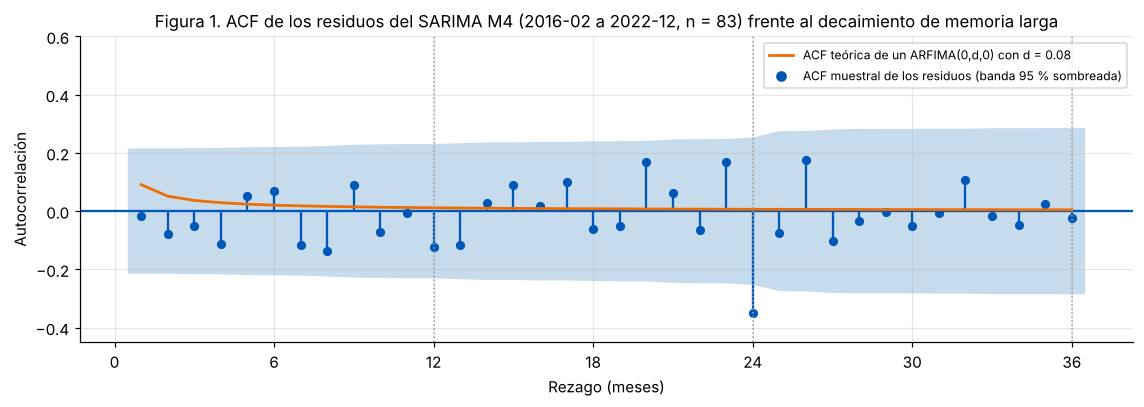

Banda 95 % = ±0.215 | rezagos fuera de banda (de 36): {24: -0.35}
Suma de la ACF muestral, rezagos 1-12 = -0.505 | rezagos 13-36 = -0.055 | ACF teórica con d = 0.08: ρ1 = 0.091, ρ12 = 0.012, ρ36 = 0.005
Rezago 24: ρ24 = -0.350 | rezagos vecinos: ρ23 = +0.169, ρ25 = -0.075 | rezagos fuera de banda esperados por azar (5 % de 36) = 1.8 | observados = 1


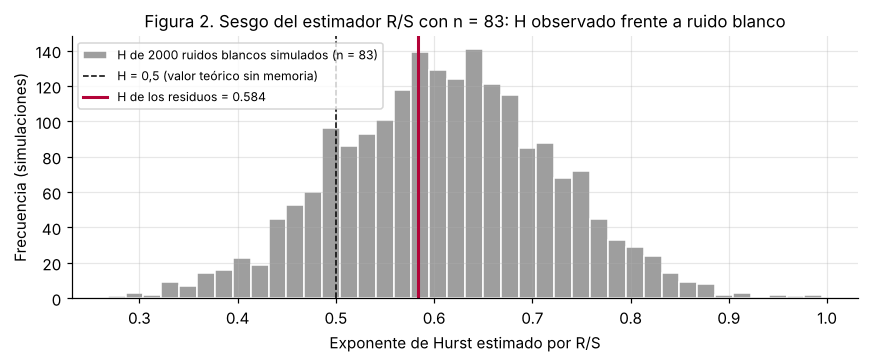

H = 0.584 | d = H - 0,5 = 0.084 | ruido blanco (n = 83): media H = 0.611, percentiles 5-95 % = [0.434; 0.791] | P(H_rb ≥ H observado) = 0.605
Ljung-Box residuos SARIMA: p(K=12) = 0.679, p(K=24) = 0.059 | tras (1-B)^d: p(K=12) = 0.508, p(K=24) = 0.023, ρ1 = -0.076 (residuos: -0.017)
Corrección ARFIMA sobre el pronóstico 2023: -0.37 % en enero → -0.01 % en diciembre | cambio medio = -0.09 GWh/mes | residuos finales (2022-10 a 2022-12): [ 0.0147  0.0078 -0.0543]
Validación 2023: SARIMA M4 RMSE = 4.122, MAE = 3.709 GWh | + corrección ARFIMA(0,d,0): RMSE = 4.192, MAE = 3.749 GWh


In [6]:
# --- (a) ACF de los residuos hasta el rezago 36 y exponente de Hurst ---
n_res = len(residuos)
banda = 1.96 / np.sqrt(n_res)
acf_res = acf(residuos, nlags=36)
hurst = calcular_exponente_hurst(residuos)       # se llama `hurst` para no sobrescribir el horizonte H = 12
d = hurst - 0.5
k = np.arange(1, 37)
acf_teorica = np.exp(gammaln(1 - d) + gammaln(k + d) - gammaln(d) - gammaln(k + 1 - d))   # ρ(k) de un ARFIMA(0,d,0)

fig, ax = plt.subplots(figsize=(10.5, 3.8))
plot_acf(residuos, lags=36, zero=False, ax=ax, title="", color=AZUL, vlines_kwargs={"colors": AZUL})
ax.plot(k, acf_teorica, color=NARANJA, lw=1.8, label=f"ACF teórica de un ARFIMA(0,d,0) con d = {d:.2f}")
ax.plot([], [], color=AZUL, marker="o", ls="", label="ACF muestral de los residuos (banda 95 % sombreada)")
for rez in (12, 24, 36):
    ax.axvline(rez, color=GRIS, ls=":", lw=1)
ax.set(xlabel="Rezago (meses)", ylabel="Autocorrelación", xticks=range(0, 37, 6),
       ylim=(min(-0.45, acf_res[1:].min() - 0.05), max(0.6, acf_res[1:].max() + 0.05)),
       title=f"Figura 1. ACF de los residuos del {MODELO} ({residuos.index[0]:%Y-%m} a {residuos.index[-1]:%Y-%m}, n = {n_res}) frente al decaimiento de memoria larga")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

fuera = {int(r): round(float(acf_res[r]), 3) for r in k if abs(acf_res[r]) > banda}
print(f"Banda 95 % = ±{banda:.3f} | rezagos fuera de banda (de 36): {fuera}")
print(f"Suma de la ACF muestral, rezagos 1-12 = {acf_res[1:13].sum():+.3f} | rezagos 13-36 = {acf_res[13:37].sum():+.3f} "
      f"| ACF teórica con d = {d:.2f}: ρ1 = {acf_teorica[0]:.3f}, ρ12 = {acf_teorica[11]:.3f}, ρ36 = {acf_teorica[35]:.3f}")

# Lectura del rezago 24 (agregado en la Sumativa): rezagos vecinos y excedencias esperadas por azar
print(f"Rezago 24: ρ24 = {acf_res[24]:+.3f} | rezagos vecinos: ρ23 = {acf_res[23]:+.3f}, ρ25 = {acf_res[25]:+.3f} | "
      f"rezagos fuera de banda esperados por azar (5 % de 36) = {0.05 * 36:.1f} | observados = {len(fuera)}")

# --- (b) Hurst frente a su distribución bajo ruido blanco con el mismo n (mismo estimador R/S de la plantilla) ---
rng = np.random.default_rng(SEMILLA)
hurst_rb = np.array([calcular_exponente_hurst(rng.standard_normal(n_res)) for _ in range(2000)])
p_rb = float(np.mean(hurst_rb >= hurst))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(hurst_rb, bins=40, color=GRIS, edgecolor="white", label="H de 2000 ruidos blancos simulados (n = %d)" % n_res)
ax.axvline(0.5, color="k", lw=1, ls="--", label="H = 0,5 (valor teórico sin memoria)")
ax.axvline(hurst, color=ROJO, lw=2, label=f"H de los residuos = {hurst:.3f}")
ax.set(xlabel="Exponente de Hurst estimado por R/S", ylabel="Frecuencia (simulaciones)",
       title="Figura 2. Sesgo del estimador R/S con n = %d: H observado frente a ruido blanco" % n_res)
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
print(f"H = {hurst:.3f} | d = H - 0,5 = {d:.3f} | ruido blanco (n = {n_res}): media H = {hurst_rb.mean():.3f}, "
      f"percentiles 5-95 % = [{np.percentile(hurst_rb, 5):.3f}; {np.percentile(hurst_rb, 95):.3f}] | "
      f"P(H_rb ≥ H observado) = {p_rb:.3f}")

# --- (c) ARFIMA(0,d,0) como contraste: residuos filtrados con (1-B)^d y corrección del pronóstico ---
filtrados = aplicar_filtro_fraccional(residuos, d)
lb_res = acorr_ljungbox(residuos, lags=[12, 24], model_df=N_ARMA)       # gl = K − parámetros ARMA (como en la S2)
lb_fil = acorr_ljungbox(filtrados, lags=[12, 24], model_df=N_ARMA + 1)  # + d
print(f"Ljung-Box residuos SARIMA: p(K=12) = {lb_res.lb_pvalue.iloc[0]:.3f}, p(K=24) = {lb_res.lb_pvalue.iloc[1]:.3f} | "
      f"tras (1-B)^d: p(K=12) = {lb_fil.lb_pvalue.iloc[0]:.3f}, p(K=24) = {lb_fil.lb_pvalue.iloc[1]:.3f}, "
      f"ρ1 = {acf(filtrados, nlags=1)[1]:+.3f} (residuos: {acf_res[1]:+.3f})")

corr_arfima = correccion_arfima(residuos, d, H)
media_log_arfima = media_log + corr_arfima
media_gwh_arfima = np.exp(media_log_arfima + sd_log ** 2 / 2)
ajuste_pct = 100 * (np.exp(corr_arfima) - 1)
print(f"Corrección ARFIMA sobre el pronóstico 2023: {ajuste_pct[0]:+.2f} % en enero → {ajuste_pct[-1]:+.2f} % en diciembre "
      f"| cambio medio = {np.mean(media_gwh_arfima - media_gwh):+.2f} GWh/mes "
      f"| residuos finales (2022-10 a 2022-12): {np.round(residuos.iloc[-3:].to_numpy(), 4)}")
met_arfima = metricas(real, media_gwh_arfima)
print(f"Validación 2023: {MODELO} RMSE = {met_sarima['RMSE']:.3f}, MAE = {met_sarima['MAE']:.3f} GWh | "
      f"+ corrección ARFIMA(0,d,0): RMSE = {met_arfima['RMSE']:.3f}, MAE = {met_arfima['MAE']:.3f} GWh")

**Resultados.** H = 0,584 y d = H − 0,5 = 0,084. Aunque H supera el valor teórico 0,5, asociado a la ausencia de memoria de largo plazo (Bianchi, 2023), con n = 83 esa diferencia no basta para concluir persistencia: el 60,5 % de 2000 ruidos blancos simulados del mismo tamaño produce un H igual o mayor (Fig. 2).

**Decaimiento de la ACF.** No hay cola positiva persistente: las autocorrelaciones son pequeñas y alternan de signo, y con d = 0,084 las autocorrelaciones teóricas quedarían bajo la banda (ρ1 = 0,091) (Fig. 1).

**Rezago 24.** Es el único fuera de ±0,215 (ρ24 = −0,35) y equivale a dos años de separación. Podría reflejar una estructura residual bianual que el SARIMA no captura por completo, pero es negativo, aislado y sin vecinos significativos, lo contrario del decaimiento lento de la memoria larga; además, en 36 rezagos se esperan 1,8 excedencias por azar. Con n = 83 se interpreta con cautela y queda como aspecto a observar en análisis futuros.

**Contraste ARFIMA(0,d,0).** La diferenciación fraccional (Granger y Joyeux, 1980; Hosking, 1981) no corrige ese rezago (Ljung-Box K = 24: p de 0,059 a 0,023; Ljung y Box, 1978) y empeora levemente el pronóstico (RMSE de 4,12 a 4,19 GWh).

**Conclusión.** No hay evidencia suficiente de memoria larga; ARFIMA queda solo como contraste.

## 2. Modelamiento de volatilidad (GARCH)

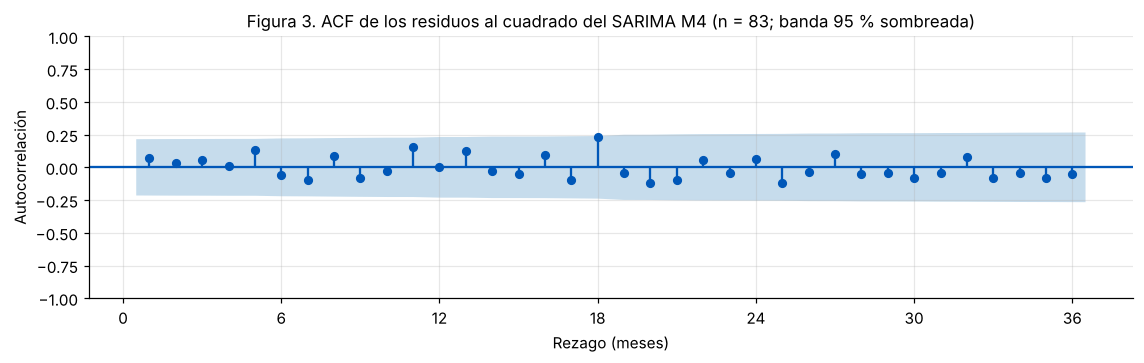

ACF de residuos² fuera de banda: {18: 0.228}


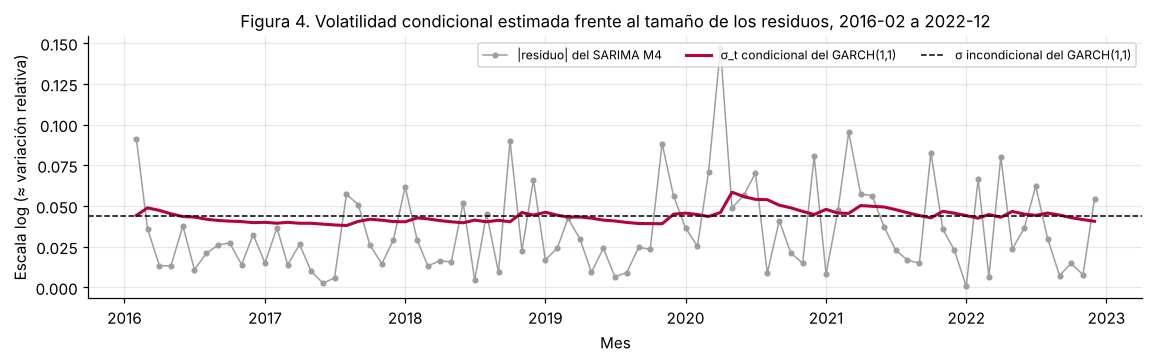

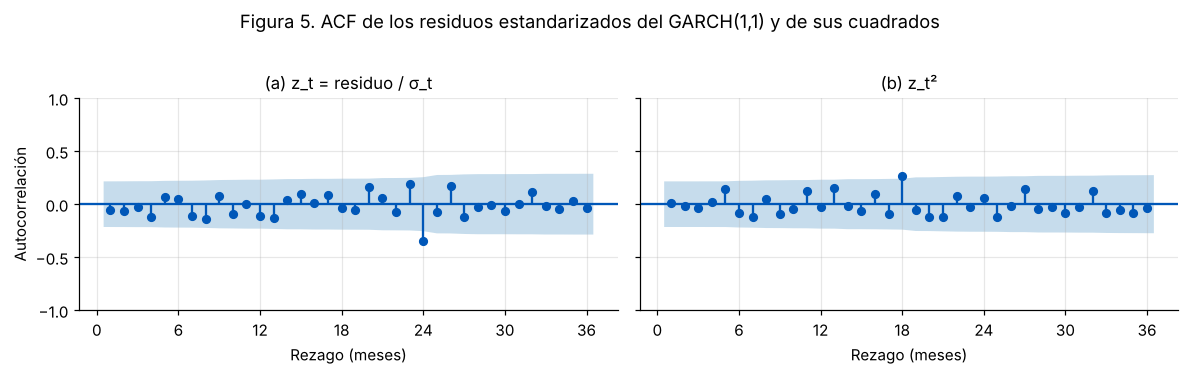

,Valor,p-valor
Prueba o parámetro,,
Ljung-Box residuos² (K = 12),Q = 7.42,0.829
ARCH-LM residuos (12 rezagos),LM = 7.98,0.786
"GARCH(1,1): ω (residuos escalados a varianza 1)",0.1565,—
"GARCH(1,1): α",0.0687,—
"GARCH(1,1): β",0.7716,—
"GARCH(1,1): α + β (debe ser menor que 1)",0.8403 (cumple),convergencia: sí
Ljung-Box z_t (K = 12),Q = 8.25,0.766
Ljung-Box z_t² (K = 12),Q = 7.06,0.853
ARCH-LM z_t (12 rezagos),—,0.740


GARCH(1,1): ω = 0.1565 | α = 0.0687 | β = 0.7716 | α + β = 0.8403 (< 1: True) | convergencia: True
Factor de escala GARCH 2023: mín = 0.9644, máx = 0.9948 | σ_t en entrenamiento: mín = 0.0380, máx = 0.0584 (σ residual = 0.0442)
Contexto: σ residual = 0.0442 en log ≈ 4.4 % del consumo mensual ≈ 4.7 GWh al nivel medio de 2022 (107.1 GWh/mes)
Mayor |residuo|: 2020-04 (-3.3 σ) | σ_t máxima: 2020-05 (0.0584) | σ_t media anual: 2016: 0.0433 | 2017: 0.0398 | 2018: 0.0416 | 2019: 0.0420 | 2020: 0.0494 | 2021: 0.0467 | 2022: 0.0438
AIC: varianza constante = 237.5 | GARCH(1,1) = 240.4 | vida media de un shock de varianza en el GARCH ajustado = ln 0,5 / ln(α + β) = 4.0 meses


In [7]:
# --- (a) Detección: ACF de residuos al cuadrado, Ljung-Box (K = 12) y ARCH-LM (12 rezagos) ---
r = residuos.to_numpy()
lb2 = acorr_ljungbox(r ** 2, lags=[12])
lm_stat, p_lm, _, _ = het_arch(r, nlags=12)

fig, ax = plt.subplots(figsize=(10.5, 3.4))
plot_acf(r ** 2, lags=36, zero=False, ax=ax, title="", color=AZUL, vlines_kwargs={"colors": AZUL})
ax.set(xlabel="Rezago (meses)", ylabel="Autocorrelación", xticks=range(0, 37, 6),
       title=f"Figura 3. ACF de los residuos al cuadrado del {MODELO} (n = {len(r)}; banda 95 % sombreada)")
plt.tight_layout(); plt.show()
acf_r2 = acf(r ** 2, nlags=36)
print("ACF de residuos² fuera de banda:", {int(j): round(float(acf_r2[j]), 3) for j in range(1, 37) if abs(acf_r2[j]) > banda})

# --- (b) GARCH(1,1) de la plantilla (restricción α + β < 1 impuesta en la optimización) ---
g = estimar_garch11(residuos, H)
u = r / r.std()                                         # misma recursión de la plantilla, para graficar σ_t
s2 = np.zeros(len(u)); s2[0] = u.var()
for t in range(1, len(u)):
    s2[t] = g["omega"] + g["alpha"] * u[t - 1] ** 2 + g["beta"] * s2[t - 1]
sigma_t = r.std() * np.sqrt(s2)                         # escala log (≈ variación relativa)
sigma_incond = r.std() * np.sqrt(g["omega"] / (1 - g["persistencia"]))

fig, ax = plt.subplots(figsize=(10.5, 3.4))
ax.plot(residuos.index, np.abs(r), color=GRIS, lw=1, marker="o", ms=3, label=f"|residuo| del {MODELO}")
ax.plot(residuos.index, sigma_t, color=ROJO, lw=2, label="σ_t condicional del GARCH(1,1)")
ax.axhline(sigma_incond, color="k", lw=1, ls="--", label="σ incondicional del GARCH(1,1)")
ax.set(xlabel="Mes", ylabel="Escala log (≈ variación relativa)",
       title=f"Figura 4. Volatilidad condicional estimada frente al tamaño de los residuos, {residuos.index[0]:%Y-%m} a {residuos.index[-1]:%Y-%m}")
ax.legend(loc="upper right", ncol=3)
plt.tight_layout(); plt.show()

# --- (c) Diagnóstico sobre los residuos estandarizados por σ_t y sus cuadrados ---
z = g["residuos_estandarizados"]
lb_z, lb_z2 = acorr_ljungbox(z, lags=[12]), acorr_ljungbox(z ** 2, lags=[12])
p_lm_z = het_arch(z, nlags=12)[1]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
for ax, serie, nombre in [(axes[0], z, "(a) z_t = residuo / σ_t"), (axes[1], z ** 2, "(b) z_t²")]:
    plot_acf(serie, lags=36, zero=False, ax=ax, title=nombre, color=AZUL, vlines_kwargs={"colors": AZUL})
    ax.set(xlabel="Rezago (meses)", xticks=range(0, 37, 6))
axes[0].set_ylabel("Autocorrelación")
fig.suptitle("Figura 5. ACF de los residuos estandarizados del GARCH(1,1) y de sus cuadrados", y=1.02)
plt.tight_layout(); plt.show()

# AIC de la varianza: GARCH(1,1) frente a varianza constante, con la misma verosimilitud gaussiana y los mismos
# residuos escalados u (compara dos modelos del mismo objeto; no es el AIC de ARFIMA frente a GARCH)
nll_garch = garch_log_verosimilitud_negativa([g["omega"], g["alpha"], g["beta"]], u)
s2_const = np.mean(u ** 2)
nll_const = 0.5 * np.sum(np.log(2 * np.pi) + np.log(s2_const) + u ** 2 / s2_const)
aic_const, aic_garch = 2 * nll_const + 2 * 1, 2 * nll_garch + 2 * 3

tabla_garch = pd.DataFrame(
    [["Ljung-Box residuos² (K = 12)", f"Q = {lb2.lb_stat.iloc[0]:.2f}", f"{lb2.lb_pvalue.iloc[0]:.3f}"],
     ["ARCH-LM residuos (12 rezagos)", f"LM = {lm_stat:.2f}", f"{p_lm:.3f}"],
     ["GARCH(1,1): ω (residuos escalados a varianza 1)", f"{g['omega']:.4f}", "—"],
     ["GARCH(1,1): α", f"{g['alpha']:.4f}", "—"],
     ["GARCH(1,1): β", f"{g['beta']:.4f}", "—"],
     ["GARCH(1,1): α + β (debe ser menor que 1)", f"{g['persistencia']:.4f} ({'cumple' if g['persistencia'] < 1 else 'NO cumple'})",
      f"convergencia: {'sí' if g['convergencia'] else 'no'}"],
     ["Ljung-Box z_t (K = 12)", f"Q = {lb_z.lb_stat.iloc[0]:.2f}", f"{lb_z.lb_pvalue.iloc[0]:.3f}"],
     ["Ljung-Box z_t² (K = 12)", f"Q = {lb_z2.lb_stat.iloc[0]:.2f}", f"{lb_z2.lb_pvalue.iloc[0]:.3f}"],
     ["ARCH-LM z_t (12 rezagos)", "—", f"{p_lm_z:.3f}"],
     ["AIC varianza constante (1 parámetro)", f"{aic_const:.1f}", "—"],
     ["AIC GARCH(1,1) (3 parámetros)", f"{aic_garch:.1f}", "—"]],
    columns=["Prueba o parámetro", "Valor", "p-valor"]).set_index("Prueba o parámetro")
display(tabla_garch.style.set_caption(f"Tabla 1. Detección de efectos ARCH y GARCH(1,1) sobre los residuos del {MODELO}"))

# --- (d) Bandas GARCH al 95 % para 2023 (en GWh) ---
inf_garch = np.exp(media_log - 1.96 * sd_log * g["escala_futura"])
sup_garch = np.exp(media_log + 1.96 * sd_log * g["escala_futura"])
print(f"GARCH(1,1): ω = {g['omega']:.4f} | α = {g['alpha']:.4f} | β = {g['beta']:.4f} | α + β = {g['persistencia']:.4f} "
      f"(< 1: {g['persistencia'] < 1}) | convergencia: {g['convergencia']}")
print(f"Factor de escala GARCH 2023: mín = {g['escala_futura'].min():.4f}, máx = {g['escala_futura'].max():.4f} "
      f"| σ_t en entrenamiento: mín = {sigma_t.min():.4f}, máx = {sigma_t.max():.4f} (σ residual = {r.std():.4f})")

# --- (e) Contexto del consumo: magnitud del residuo en GWh y ubicación temporal de la volatilidad estimada ---
nivel_2022 = y["2022-01":"2022-12"].mean()
sigma_serie = pd.Series(sigma_t, index=residuos.index)
mes_mayor = residuos.abs().idxmax()
vida_media = np.log(0.5) / np.log(g["persistencia"])
print(f"Contexto: σ residual = {r.std():.4f} en log ≈ {100 * r.std():.1f} % del consumo mensual ≈ {r.std() * nivel_2022:.1f} GWh "
      f"al nivel medio de 2022 ({nivel_2022:.1f} GWh/mes)")
print(f"Mayor |residuo|: {mes_mayor:%Y-%m} ({residuos[mes_mayor] / r.std():+.1f} σ) | σ_t máxima: {sigma_serie.idxmax():%Y-%m} "
      f"({sigma_serie.max():.4f}) | σ_t media anual: "
      + " | ".join(f"{a}: {v:.4f}" for a, v in sigma_serie.groupby(sigma_serie.index.year).mean().items()))
print(f"AIC: varianza constante = {aic_const:.1f} | GARCH(1,1) = {aic_garch:.1f} | vida media de un shock de varianza en el "
      f"GARCH ajustado = ln 0,5 / ln(α + β) = {vida_media:.1f} meses")

**Resultados.** La ACF de los residuos² solo excede la banda en el rezago 18 (0,228), esperable por azar (Fig. 3). Ljung-Box sobre los cuadrados (K = 12; p = 0,829) y ARCH-LM (p = 0,786) no detectan efectos ARCH (Engle, 1982). El GARCH(1,1) (Bollerslev, 1986; Sheppard, s. f.) converge con ω = 0,1565 (residuos escalados), α = 0,0687, β = 0,7716 y α + β = 0,8403 < 1. Sus residuos estandarizados no conservan efectos ARCH (z_t: p ≈ 0,77; z_t²: p ≈ 0,85; ARCH-LM: p ≈ 0,74); z_t mantiene el rezago 24, propio de la media (Fig. 5). El AIC favorece la varianza constante (237,5 frente a 240,4; Tabla 1).

**Contexto del consumo.** La serie es consumo eléctrico mensual de un segmento comercial, no un retorno financiero. Tras remover con el SARIMA tendencia, estacionalidad y dependencia de corto plazo, el residuo típico equivale a cerca de 4,4 % del consumo mensual (≈ 4,7 GWh en 2022). Con α pequeño, un mes atípico apenas altera la varianza del mes siguiente. La principal alza de σ_t sigue al mayor residuo (abril de 2020) y se atenúa con una vida media de unos cuatro meses (Fig. 4): un episodio puntual, no un agrupamiento persistente. α + β describe el modelo ajustado, pero no prueba que GARCH sea necesario.

**Conclusión.** En esta serie, periodo y residuos, la variabilidad es suficientemente estable para mantener la varianza constante; GARCH(1,1) queda como contraste.

## 3. Contraste con el modelo clásico y consistencia de conclusiones

,RMSE,MAE,Cobertura,Meses dentro,Ancho medio
Pronóstico o intervalo,,,,,
SARIMA M4,4.12,3.71,—,—,—
"SARIMA M4 + corrección ARFIMA(0,d,0)",4.19,3.75,—,—,—
Naive estacional,7.26,6.53,—,—,—
IC 95 % SARIMA M4,—,—,100%,12/12,46.26
IC 95 % SARIMA M4 + bandas GARCH,—,—,100%,12/12,45.64


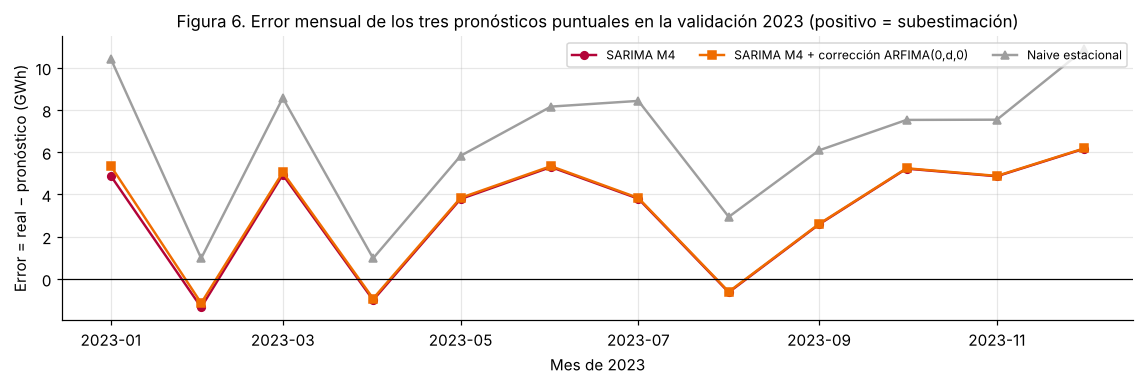

Reducción del SARIMA M4 frente al naive estacional: RMSE 43.3 % | MAE 43.2 %
ME (sesgo): SARIMA = +3.21 | +ARFIMA = +3.30 | naive = +6.53 GWh | meses subestimados por el SARIMA: 9/12 | meses en que ARFIMA empeora |e|: 9/12
ΔRMSE (ARFIMA − SARIMA) = +0.07 GWh | máxima diferencia de ancho mensual GARCH − SARIMA = 0.8684 GWh | margen mínimo al límite superior del IC SARIMA = 6.43 GWh (2023-01)


In [8]:
# Contraste en validación 2023 (GWh). No se comparan AIC entre ARFIMA y GARCH: modelan aspectos distintos
# (media condicional frente a varianza condicional); el criterio común es el desempeño fuera de muestra.
real = y_val.to_numpy()
ETQ_ARFIMA = f"{MODELO} + corrección ARFIMA(0,d,0)"
puntuales = {MODELO: media_gwh.to_numpy(),
             ETQ_ARFIMA: media_gwh_arfima.to_numpy(),
             "Naive estacional": naive}
intervalos = {f"IC 95 % {MODELO}": (inf_sarima.to_numpy(), sup_sarima.to_numpy()),
              f"IC 95 % {MODELO} + bandas GARCH": (inf_garch.to_numpy(), sup_garch.to_numpy())}

filas = [{"Pronóstico o intervalo": n, **metricas(real, p)} for n, p in puntuales.items()]
filas += [{"Pronóstico o intervalo": n, **cobertura_y_ancho(real, lo, hi)} for n, (lo, hi) in intervalos.items()]
tabla_contraste = pd.DataFrame(filas).set_index("Pronóstico o intervalo")
tabla_contraste["Meses dentro"] = (tabla_contraste["Cobertura"] * len(real)).round().astype("Int64").astype(str) + f"/{len(real)}"
tabla_contraste.loc[tabla_contraste["Cobertura"].isna(), "Meses dentro"] = "—"
display(tabla_contraste[["RMSE", "MAE", "Cobertura", "Meses dentro", "Ancho medio"]]
        .style.format({"RMSE": "{:.2f}", "MAE": "{:.2f}", "Cobertura": "{:.0%}", "Ancho medio": "{:.2f}"}, na_rep="—")
        .set_caption("Tabla 2. Contraste en validación 2023 (GWh): pronóstico puntual (RMSE, MAE) e intervalos al 95 % (cobertura, ancho medio)"))

errores = {n: real - p for n, p in puntuales.items()}
fig, ax = plt.subplots(figsize=(10.5, 3.6))
for (n, e), color, marca in zip(errores.items(), (ROJO, NARANJA, GRIS), ("o", "s", "^")):
    ax.plot(y_val.index, e, color=color, lw=1.6, marker=marca, ms=5, label=n)
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="Mes de 2023", ylabel="Error = real − pronóstico (GWh)",
       title="Figura 6. Error mensual de los tres pronósticos puntuales en la validación 2023 (positivo = subestimación)")
ax.legend(loc="upper right", ncol=3)
plt.tight_layout(); plt.show()

e_s, e_a = errores[MODELO], errores[ETQ_ARFIMA]
m_n = metricas(real, naive)
cob_sarima = cobertura_y_ancho(real, inf_sarima, sup_sarima)
cob_garch = cobertura_y_ancho(real, inf_garch, sup_garch)
print(f"Reducción del {MODELO} frente al naive estacional: RMSE {100 * (1 - met_sarima['RMSE'] / m_n['RMSE']):.1f} % | "
      f"MAE {100 * (1 - met_sarima['MAE'] / m_n['MAE']):.1f} %")
print(f"ME (sesgo): SARIMA = {e_s.mean():+.2f} | +ARFIMA = {e_a.mean():+.2f} | naive = {errores['Naive estacional'].mean():+.2f} GWh "
      f"| meses subestimados por el SARIMA: {(e_s > 0).sum()}/12 | meses en que ARFIMA empeora |e|: {(np.abs(e_a) > np.abs(e_s)).sum()}/12")
dif_ancho = np.max(np.abs((sup_garch - inf_garch) - (sup_sarima - inf_sarima)))
print(f"ΔRMSE (ARFIMA − SARIMA) = {met_arfima['RMSE'] - met_sarima['RMSE']:+.2f} GWh "
      f"| máxima diferencia de ancho mensual GARCH − SARIMA = {dif_ancho:.4f} GWh "
      f"| margen mínimo al límite superior del IC SARIMA = {np.min(sup_sarima.to_numpy() - real):.2f} GWh "
      f"({y_val.index[np.argmin(sup_sarima.to_numpy() - real)]:%Y-%m})")

**Resultados.** En la validación 2023 (Tabla 2), el SARIMA M4 obtiene RMSE = 4,12 y MAE = 3,71 GWh (Hyndman y Athanasopoulos, 2021; Hyndman et al., 2026), y el naive estacional, 7,26 y 6,53 (reducciones de 43,3 % y 43,2 %). Con la corrección ARFIMA(0,d,0), RMSE = 4,19 y MAE = 3,75, y el |error| aumenta en 9 de 12 meses. El error medio es +3,2 GWh (SARIMA), +3,3 (ARFIMA) y +6,5 (naive): los tres subestiman (Fig. 6). Ambos intervalos al 95 % cubren 12 de 12 meses, con ancho medio de 46,26 GWh (SARIMA) y 45,64 GWh (bandas GARCH). No se comparan AIC entre ARFIMA y GARCH, porque modelan aspectos distintos.

**Interpretación.** Ninguna diferencia es sustantiva. El aumento de RMSE con ARFIMA (+0,07 GWh) es pequeño frente al error típico mensual (MAE ≈ 3,7 GWh) y desfavorece la extensión. Las bandas GARCH se estrechan 0,6 GWh en promedio (como máximo 0,87) sin cambiar la cobertura, y con 12 meses una cobertura de 12/12 en ambos no permite juzgar su calibración. Limitaciones:

- **SARIMA M4:** subestima 9 de 12 meses.
- **SARIMA + ARFIMA:** no corrige ese sesgo y aumenta levemente RMSE y MAE.
- **SARIMA + bandas GARCH:** intervalos casi idénticos, con tres parámetros más.
- **Naive estacional:** errores claramente mayores.

Ninguna extensión justifica más complejidad.

## 4. Selección del modelo con evidencia cuantitativa

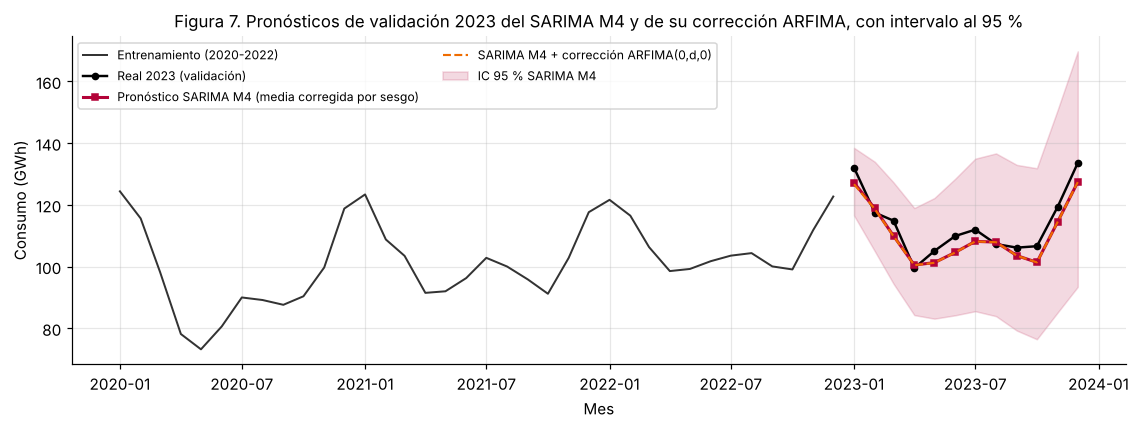

Energía 2023: real = 1363.9 GWh | pronóstico SARIMA M4 = 1325.4 GWh (diferencia = -38.6 GWh; -2.8 %)
Meses de 2023 dentro del IC 95 %: 12/12 | meses con valor real sobre la media pronosticada: 9/12


In [9]:
# Evidencia reunida para la selección final. El modelo NO se elige automáticamente en esta celda.
y_hist = y["2020-01":"2022-12"]
fig, ax = plt.subplots(figsize=(10.5, 4.0))
ax.plot(y_hist.index, y_hist, color="#333333", lw=1.3, label="Entrenamiento (2020-2022)")
ax.plot(y_val.index, y_val, color="k", lw=1.6, marker="o", ms=4, label="Real 2023 (validación)")
ax.plot(y_val.index, media_gwh, color=ROJO, lw=2, marker="s", ms=4, label=f"Pronóstico {MODELO} (media corregida por sesgo)")
ax.plot(y_val.index, media_gwh_arfima, color=NARANJA, lw=1.4, ls="--", label=ETQ_ARFIMA)
ax.fill_between(y_val.index, inf_sarima, sup_sarima, color=ROJO, alpha=0.15, label=f"IC 95 % {MODELO}")
ax.set(xlabel="Mes", ylabel="Consumo (GWh)",
       title=f"Figura 7. Pronósticos de validación 2023 del {MODELO} y de su corrección ARFIMA, con intervalo al 95 %")
ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

total_real, total_pron = real.sum(), media_gwh.sum()
print(f"Energía 2023: real = {total_real:.1f} GWh | pronóstico {MODELO} = {total_pron:.1f} GWh "
      f"(diferencia = {total_pron - total_real:+.1f} GWh; {100 * (total_pron / total_real - 1):+.1f} %)")
print(f"Meses de 2023 dentro del IC 95 %: {int(((real >= inf_sarima) & (real <= sup_sarima)).sum())}/12 | "
      f"meses con valor real sobre la media pronosticada: {int((real > media_gwh.to_numpy()).sum())}/12")

f3 = lambda x: f"{x:.3f}"
evidencia = [
    ("Memoria larga", "Exponente de Hurst (R/S)", f3(hurst)),
    ("Memoria larga", "d = H − 0,5", f3(d)),
    ("Memoria larga", f"P(H de ruido blanco ≥ H observado), n = {n_res}", f3(p_rb)),
    ("Memoria larga", f"Rezagos de la ACF residual fuera de ±{banda:.3f} (de 36)", str(fuera) if fuera else "ninguno"),
    ("Memoria larga", f"Ljung-Box residuos {MODELO}: p (K = 12 / K = 24)", f"{lb_res.lb_pvalue.iloc[0]:.3f} / {lb_res.lb_pvalue.iloc[1]:.3f}"),
    ("Volatilidad", "Ljung-Box residuos² (K = 12): p", f3(lb2.lb_pvalue.iloc[0])),
    ("Volatilidad", "ARCH-LM (12 rezagos): p", f3(p_lm)),
    ("Volatilidad", "GARCH(1,1): ω / α / β", f"{g['omega']:.4f} / {g['alpha']:.4f} / {g['beta']:.4f}"),
    ("Volatilidad", "GARCH(1,1): α + β (< 1)", f"{g['persistencia']:.4f} ({'cumple' if g['persistencia'] < 1 else 'NO cumple'})"),
    ("Volatilidad", "Ljung-Box z_t / z_t² (K = 12): p", f"{lb_z.lb_pvalue.iloc[0]:.3f} / {lb_z2.lb_pvalue.iloc[0]:.3f}"),
] + [("Pronóstico 2023", f"{n}: RMSE / MAE (GWh)", f"{tabla_contraste.loc[n, 'RMSE']:.2f} / {tabla_contraste.loc[n, 'MAE']:.2f}")
     for n in puntuales] \
  + [("Intervalos 2023", f"{n}: cobertura / ancho medio (GWh)",
      f"{tabla_contraste.loc[n, 'Cobertura']:.0%} ({tabla_contraste.loc[n, 'Meses dentro']}) / {tabla_contraste.loc[n, 'Ancho medio']:.2f}")
     for n in intervalos]
tabla_evidencia = pd.DataFrame(evidencia, columns=["Bloque", "Evidencia", "Valor"]).set_index(["Bloque", "Evidencia"])
display(tabla_evidencia.style.set_caption("Tabla 3. Evidencia cuantitativa disponible para la decisión final (calculada en esta ejecución)"))

### Selección final

La decisión integra los bloques de la Tabla 3, no una sola métrica:

- **Dependencia temporal.** La ACF residual no decae lentamente, H = 0,584 es compatible con ruido blanco de n = 83 y ARFIMA no mejora el diagnóstico ni el pronóstico.
- **Volatilidad.** Ljung-Box de residuos² (p = 0,829) y ARCH-LM (p = 0,786) no rechazan, los residuos estandarizados no conservan efectos ARCH y el AIC favorece la varianza constante.
- **Pronóstico.** M4 tiene el menor RMSE y MAE (4,12 / 3,71 GWh) y reduce cerca de 43 % el error del naive; las bandas GARCH no cambian la cobertura.
- **Parsimonia.** M4 estima un solo coeficiente (Φ1 = −0,311); ARFIMA agrega d, y GARCH, ω, α y β, sin beneficio verificable.

**Decisión.** Se mantiene **M4 = SARIMA(0,1,0)(1,1,0)₁₂** (`order=(0,1,0)`, `seasonal_order=(1,1,0,12)`) para la Semana 4. Es coherente con el fenómeno: el consumo comercial mensual está dominado por la tendencia y la estacionalidad anual, que M4 recoge con las diferencias regular y estacional, y sus residuos no muestran persistencia larga ni volatilidad agrupada.

**Pronóstico 2023.** M4 proyecta 1325,4 GWh frente a 1363,9 GWh observados (−2,8 %), con los 12 meses dentro del IC 95 % (Fig. 7). Para planificar el suministro conviene considerar también el límite superior del intervalo.

**Limitaciones.** M4 subestima 9 de 12 meses, la ACF residual conserva un rezago 24 aislado y la evidencia descansa en 83 residuos y 12 meses de validación.

## Conclusiones

1. **Qué se evaluó.** Si la memoria larga (ARFIMA) o la volatilidad condicional (GARCH) aportan al modelo seleccionado en la Sumativa 2, M4 = SARIMA(0,1,0)(1,1,0)₁₂ sobre log(consumo), usando los 83 residuos del entrenamiento 2015-01 a 2022-12 y la validación 2023.
2. **Memoria larga.** No hay evidencia suficiente. H = 0,584 (d = 0,084) es compatible con lo que produce el ruido blanco con 83 observaciones, la ACF no decae lentamente y la corrección ARFIMA empeora levemente el pronóstico (RMSE de 4,12 a 4,19 GWh). El rezago 24 (−0,35) es negativo y aislado, por lo que no corresponde al patrón de memoria larga.
3. **Volatilidad.** No hay evidencia estadística suficiente de heterocedasticidad condicional: Ljung-Box sobre los cuadrados (p = 0,829) y ARCH-LM (p = 0,786) no rechazan, y los residuos estandarizados no conservan efectos ARCH. En este consumo eléctrico mensual, la principal alza de volatilidad estimada sigue al shock de 2020 y se disipa; la persistencia α + β = 0,8403 no basta, por sí sola, para afirmar efectos ARCH.
4. **Comparación y selección.** El SARIMA M4 obtiene el menor error en 2023 (RMSE 4,12 y MAE 3,71 GWh) y supera ampliamente al naive estacional (7,26 y 6,53). Las bandas GARCH mantienen la cobertura de 12/12 y apenas reducen el ancho medio (de 46,26 a 45,64 GWh). Por esta razón, M4 pasa sin cambios a la Semana 4.
5. **Limitaciones.** La muestra residual es corta y la validación cubre solo 12 meses, por lo que las diferencias pequeñas deben tomarse con precaución. M4 subestima 9 de 12 meses de 2023 (−2,8 % en el total anual), y el rezago 24 aislado de la ACF residual debe observarse cuando se amplíe la muestra. La ausencia de evidencia no demuestra que no exista memoria larga o heterocedasticidad; solo indica que estos datos no permiten detectarlas. Los resultados son propios de esta serie y 2024 no se utilizó.

## Control de reproducibilidad

In [10]:
# Verificaciones finales: partición temporal, modelo base y coherencia de las métricas impresas
comprobaciones = {
    "2024 no se utiliza (ni en el ajuste, ni en los residuos, ni en la validación)":
        sarima.fittedvalues.index.max() < pd.Timestamp("2024-01-01") and residuos.index.max() < pd.Timestamp("2024-01-01")
        and y_val.index.max() < pd.Timestamp("2024-01-01") and media_gwh.index.max() < pd.Timestamp("2024-01-01"),
    "entrenamiento de 2015-01 a 2022-12 (96 meses)":
        log_train.index.min() == pd.Timestamp("2015-01-01") and log_train.index.max() == pd.Timestamp("2022-12-01")
        and sarima.nobs == 96,
    "validación = 12 meses de 2023 y pronóstico alineado con ella":
        y_val.index.equals(pd.date_range("2023-01-01", periods=12, freq="MS")) and media_gwh.index.equals(y_val.index),
    "frecuencia mensual (MS)": log_train.index.freqstr == "MS",
    "modelo base = SARIMA(0,1,0)(1,1,0,12)":
        tuple(sarima.model.order) == (0, 1, 0) and tuple(sarima.model.seasonal_order) == (1, 1, 0, 12),
    "sin variables exógenas en el SARIMA base": EXOGENAS is None and sarima.model.k_exog == 0
        and not any(p in sarima.params.index for p in ("covid", "agudo")),
    "RMSE y MAE del SARIMA reproducen la Sumativa 2 (4,12 / 3,71 GWh)":
        all(abs(met_sarima[k] - v) < 0.01 for k, v in METRICAS_S2.items()),
    "métricas de la Tabla 2 = métricas recalculadas":
        all(np.isclose(tabla_contraste.loc[n, k], metricas(real, p)[k]) for n, p in puntuales.items() for k in ("RMSE", "MAE"))
        and np.isclose(tabla_contraste.loc[MODELO, "RMSE"], met_sarima["RMSE"])
        and np.isclose(tabla_contraste.loc[ETQ_ARFIMA, "RMSE"], met_arfima["RMSE"]),
    "cobertura y ancho de la Tabla 2 = valores recalculados":
        all(np.isclose(tabla_contraste.loc[n, k], cobertura_y_ancho(real, lo, hi)[k])
            for n, (lo, hi) in intervalos.items() for k in ("Cobertura", "Ancho medio")),
    "Tabla 3 (evidencia) = variables calculadas":
        tabla_evidencia.loc[("Memoria larga", "Exponente de Hurst (R/S)"), "Valor"] == f"{hurst:.3f}"
        and tabla_evidencia.loc[("Volatilidad", "ARCH-LM (12 rezagos): p"), "Valor"] == f"{p_lm:.3f}"
        and tabla_evidencia.loc[("Pronóstico 2023", f"{MODELO}: RMSE / MAE (GWh)"), "Valor"]
            == f"{met_sarima['RMSE']:.2f} / {met_sarima['MAE']:.2f}",
    "GARCH(1,1): α + β < 1": g["persistencia"] < 1,
    "naive estacional = valores observados de 2022 (no usa 2023 ni 2024)":
        np.array_equal(naive, y["2022-01":"2022-12"].to_numpy()),
}

# Cifras citadas en el texto (Hoja, interpretaciones y conclusiones) frente a las calculadas en esta ejecución,
# al mismo número de decimales con que aparecen en el texto
CITADAS = {
    "H": (hurst, 0.584, 3), "d": (d, 0.084, 3), "P(H_rb ≥ H)": (p_rb, 0.605, 3),
    "ρ24": (acf_res[24], -0.35, 2),
    "Ljung-Box K=24 residuos": (lb_res.lb_pvalue.iloc[1], 0.059, 3), "Ljung-Box K=24 tras (1-B)^d": (lb_fil.lb_pvalue.iloc[1], 0.023, 3),
    "Ljung-Box residuos²": (lb2.lb_pvalue.iloc[0], 0.829, 3), "ARCH-LM": (p_lm, 0.786, 3),
    "ω": (g["omega"], 0.1565, 4), "α": (g["alpha"], 0.0687, 4), "β": (g["beta"], 0.7716, 4), "α + β": (g["persistencia"], 0.8403, 4),
    "Ljung-Box z_t": (lb_z.lb_pvalue.iloc[0], 0.77, 2), "Ljung-Box z_t²": (lb_z2.lb_pvalue.iloc[0], 0.85, 2), "ARCH-LM z_t": (p_lm_z, 0.74, 2),
    "AIC varianza constante": (aic_const, 237.5, 1), "AIC GARCH": (aic_garch, 240.4, 1),
    "RMSE SARIMA": (met_sarima["RMSE"], 4.12, 2), "MAE SARIMA": (met_sarima["MAE"], 3.71, 2),
    "RMSE ARFIMA": (met_arfima["RMSE"], 4.19, 2), "MAE ARFIMA": (met_arfima["MAE"], 3.75, 2),
    "RMSE naive": (m_n["RMSE"], 7.26, 2), "MAE naive": (m_n["MAE"], 6.53, 2),
    "ancho SARIMA": (cob_sarima["Ancho medio"], 46.26, 2), "ancho GARCH": (cob_garch["Ancho medio"], 45.64, 2),
    "cobertura SARIMA": (cob_sarima["Cobertura"], 1.0, 2), "cobertura GARCH": (cob_garch["Cobertura"], 1.0, 2),
    "energía pronosticada 2023": (total_pron, 1325.4, 1), "energía real 2023": (total_real, 1363.9, 1),
    "meses subestimados": (int((e_s > 0).sum()), 9, 0),
}
distintas = {k: (f"{float(v):.{dec}f}", f"{cit:.{dec}f}") for k, (v, cit, dec) in CITADAS.items() if f"{float(v):.{dec}f}" != f"{cit:.{dec}f}"}
comprobaciones[f"las {len(CITADAS)} cifras citadas en el texto coinciden con esta ejecución"] = not distintas
if distintas:
    print("Cifras del texto que difieren de esta ejecución (calculada, citada):", distintas)

for nombre, ok in comprobaciones.items():
    print(f"[{'OK' if ok else 'FALLA'}] {nombre}")
assert all(comprobaciones.values()), "alguna verificación de reproducibilidad falló"
print(f"Todas las verificaciones ({len(comprobaciones)}) se cumplen.")

[OK] 2024 no se utiliza (ni en el ajuste, ni en los residuos, ni en la validación)
[OK] entrenamiento de 2015-01 a 2022-12 (96 meses)
[OK] validación = 12 meses de 2023 y pronóstico alineado con ella
[OK] frecuencia mensual (MS)
[OK] modelo base = SARIMA(0,1,0)(1,1,0,12)
[OK] sin variables exógenas en el SARIMA base
[OK] RMSE y MAE del SARIMA reproducen la Sumativa 2 (4,12 / 3,71 GWh)
[OK] métricas de la Tabla 2 = métricas recalculadas
[OK] cobertura y ancho de la Tabla 2 = valores recalculados
[OK] Tabla 3 (evidencia) = variables calculadas
[OK] GARCH(1,1): α + β < 1
[OK] naive estacional = valores observados de 2022 (no usa 2023 ni 2024)
[OK] las 30 cifras citadas en el texto coinciden con esta ejecución
Todas las verificaciones (13) se cumplen.


## Referencias (APA)

Bianchi, F. M. (2023). *Time series analysis with Python* [Repositorio de GitHub]. https://github.com/FilippoMB/python-time-series-handbook

Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, *31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, *50*(4), 987–1007. https://doi.org/10.2307/1912773

Granger, C. W. J., y Joyeux, R. (1980). An introduction to long-memory time series models and fractional differencing. *Journal of Time Series Analysis*, *1*(1), 15–29. https://doi.org/10.1111/j.1467-9892.1980.tb00297.x

Hosking, J. R. M. (1981). Fractional differencing. *Biometrika*, *68*(1), 165–176. https://doi.org/10.1093/biomet/68.1.165

Hurst, H. E. (1951). Long-term storage capacity of reservoirs. *Transactions of the American Society of Civil Engineers*, *116*(1), 770–799. https://doi.org/10.1061/TACEAT.0006518

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Hyndman, R. J., Athanasopoulos, G., Garza, A., Challu, C., Mergenthaler, M., y Olivares, K. G. (2026). *Forecasting: Principles and practice, the Pythonic way*. OTexts. https://otexts.com/fpppy/

Ljung, G. M., y Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika*, *65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Rosas, H. (2026, 12 de octubre). *MCDI505 · Guía de compañía · Semana 3* [Material docente]. Universidad Andrés Bello.

Seabold, S., y Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Sheppard, K. (s. f.). *arch: Autoregressive conditional heteroskedasticity models in Python* [Documentación de software]. https://arch.readthedocs.io/

Universidad Andrés Bello. (s. f.). *MCDI505 — Sesión 3: Modelos avanzados de series temporales y análisis de volatilidad* [Notebook de Jupyter]. Material docente del curso, Magíster en Ciencia de Datos e Inteligencia Artificial.

## Declaración de uso de Inteligencia Artificial

| Pregunta | Respuesta |
|---|---|
| ¿Utilizó herramientas de inteligencia artificial en esta entrega? | Sí. Se utilizaron herramientas de inteligencia artificial como apoyo durante el desarrollo y revisión de la entrega. |
| ¿Para qué se utilizaron? | Se utilizaron para apoyar la organización de ideas, revisar la coherencia del análisis, detectar posibles omisiones y mejorar la redacción académica del notebook. |
| ¿Cómo se verificaron sus aportes? | Los aportes fueron contrastados con los resultados obtenidos mediante la ejecución del notebook, las instrucciones y guía de la asignatura, la bibliografía utilizada y los controles de reproducibilidad implementados. |

Los resultados numéricos y las decisiones metodológicas se sustentan en la ejecución del código y en la evidencia obtenida durante el análisis.